In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = '/content/drive/MyDrive/slr_project'
os.makedirs(BASE, exist_ok=True)

Mounted at /content/drive


In [2]:
from google.colab import files
uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [3]:
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Copy the exact name from the dataset page: "Download → kaggle datasets download -d owner/name"
!kaggle datasets download -d risangbaskoro/wlasl-processed -p /content/wlasl --unzip

Dataset URL: https://www.kaggle.com/datasets/risangbaskoro/wlasl-processed
License(s): other
100% 4.82G/4.82G [01:02<00:00, 82.9MB/s]



In [4]:
!ls /content/wlasl
!ls /content/wlasl/videos | head
!ls /content/wlasl/videos | wc -l     # roughly 12k files if all are included

missing.txt	nslt_100.json	nslt_300.json  wlasl_class_list.txt
nslt_1000.json	nslt_2000.json	videos	       WLASL_v0.3.json
00335.mp4
00336.mp4
00338.mp4
00339.mp4
00341.mp4
00376.mp4
00377.mp4
00381.mp4
00382.mp4
00384.mp4
11980


In [5]:
import os, json, pandas as pd, shutil
DATA = '/content/wlasl'
VIDEO_DIR = f'{DATA}/videos'
BASE = '/content/drive/MyDrive/slr_project'      # after mounting Drive

In [6]:
nslt = json.load(open(f'{DATA}/nslt_100.json'))
os.makedirs(f'{BASE}/videos100', exist_ok=True)

copied, absent = 0, []
for vid in nslt:
    src = f'{VIDEO_DIR}/{vid}.mp4'
    if os.path.exists(src):
        shutil.copy(src, f'{BASE}/videos100/{vid}.mp4'); copied += 1
    else:
        absent.append(vid)
print('copied:', copied, '| not found:', len(absent))

copied: 1013 | not found: 1025


In [8]:
os.makedirs(f'{BASE}/metadata', exist_ok=True)

metadata_files = [
    'WLASL_v0.3.json',
    'nslt_100.json',
    'wlasl_class_list.txt'
]

for filename in metadata_files:
    shutil.copy(
        f'{DATA}/{filename}',
        f'{BASE}/metadata/{filename}'
    )

In [9]:
import os, json
import pandas as pd
import cv2
import matplotlib.pyplot as plt

BASE = '/content/drive/MyDrive/slr_project'
META = f'{BASE}/metadata'
VIDEO_DIR = f'{BASE}/videos100'

# Confirm everything is where we expect
print(os.listdir(META))
print(len(os.listdir(VIDEO_DIR)), 'videos in videos100')

['WLASL_v0.3.json', 'nslt_100.json', 'wlasl_class_list.txt']
1013 videos in videos100


In [10]:
meta = json.load(open(f'{META}/WLASL_v0.3.json'))

rows = []
for entry in meta:
    for inst in entry['instances']:
        rows.append({
            'video_id': str(inst['video_id']),
            'gloss': entry['gloss'],
            'signer_id': inst.get('signer_id'),
            'frame_start': inst.get('frame_start'),
            'frame_end': inst.get('frame_end'),
        })
meta_df = pd.DataFrame(rows)

nslt = json.load(open(f'{META}/nslt_100.json'))
sel = pd.DataFrame([{
    'video_id': str(k),
    'subset': v['subset'],        # train / val / test
    'class_id': v['action'][0],
} for k, v in nslt.items()])

df = sel.merge(meta_df, on='video_id', how='left')
print(df.shape)
print('classes:', df['gloss'].nunique())
print('rows with no gloss (merge failed):', df['gloss'].isna().sum())
df.head()

(2038, 7)
classes: 100
rows with no gloss (merge failed): 0


,video_id,subset,class_id,gloss,signer_id,frame_start,frame_end
0,05237,train,77,basketball,20,1,-1
1,69422,val,27,orange,118,1,-1
2,10899,train,82,city,5,1,-1
3,10898,val,82,city,11,1,-1
4,10893,train,82,city,42,1,-1


In [11]:
def check(vid):
    path = f'{VIDEO_DIR}/{vid}.mp4'
    if not os.path.exists(path):
        return 'missing'
    cap = cv2.VideoCapture(path)
    ok, _ = cap.read()
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
    return 'ok' if (ok and n > 0) else 'corrupted'

df['status'] = df['video_id'].apply(check)
print(df['status'].value_counts())
print(pd.crosstab(df['subset'], df['status']))     # are missing videos concentrated in one split?

status
missing    1025
ok         1013
Name: count, dtype: int64
status  missing   ok
subset              
test        158  100
train       694  748
val         173  165


In [12]:
df.to_csv(f'{BASE}/wlasl100_manifest.csv', index=False)

ok = df[df['status'] == 'ok'].copy()
print('usable videos:', len(ok))

usable videos: 1013


count    100.000000
mean      10.130000
std        2.389603
min        5.000000
25%        9.000000
50%       10.000000
75%       12.000000
max       16.000000
dtype: float64
largest/smallest class ratio: 3.2


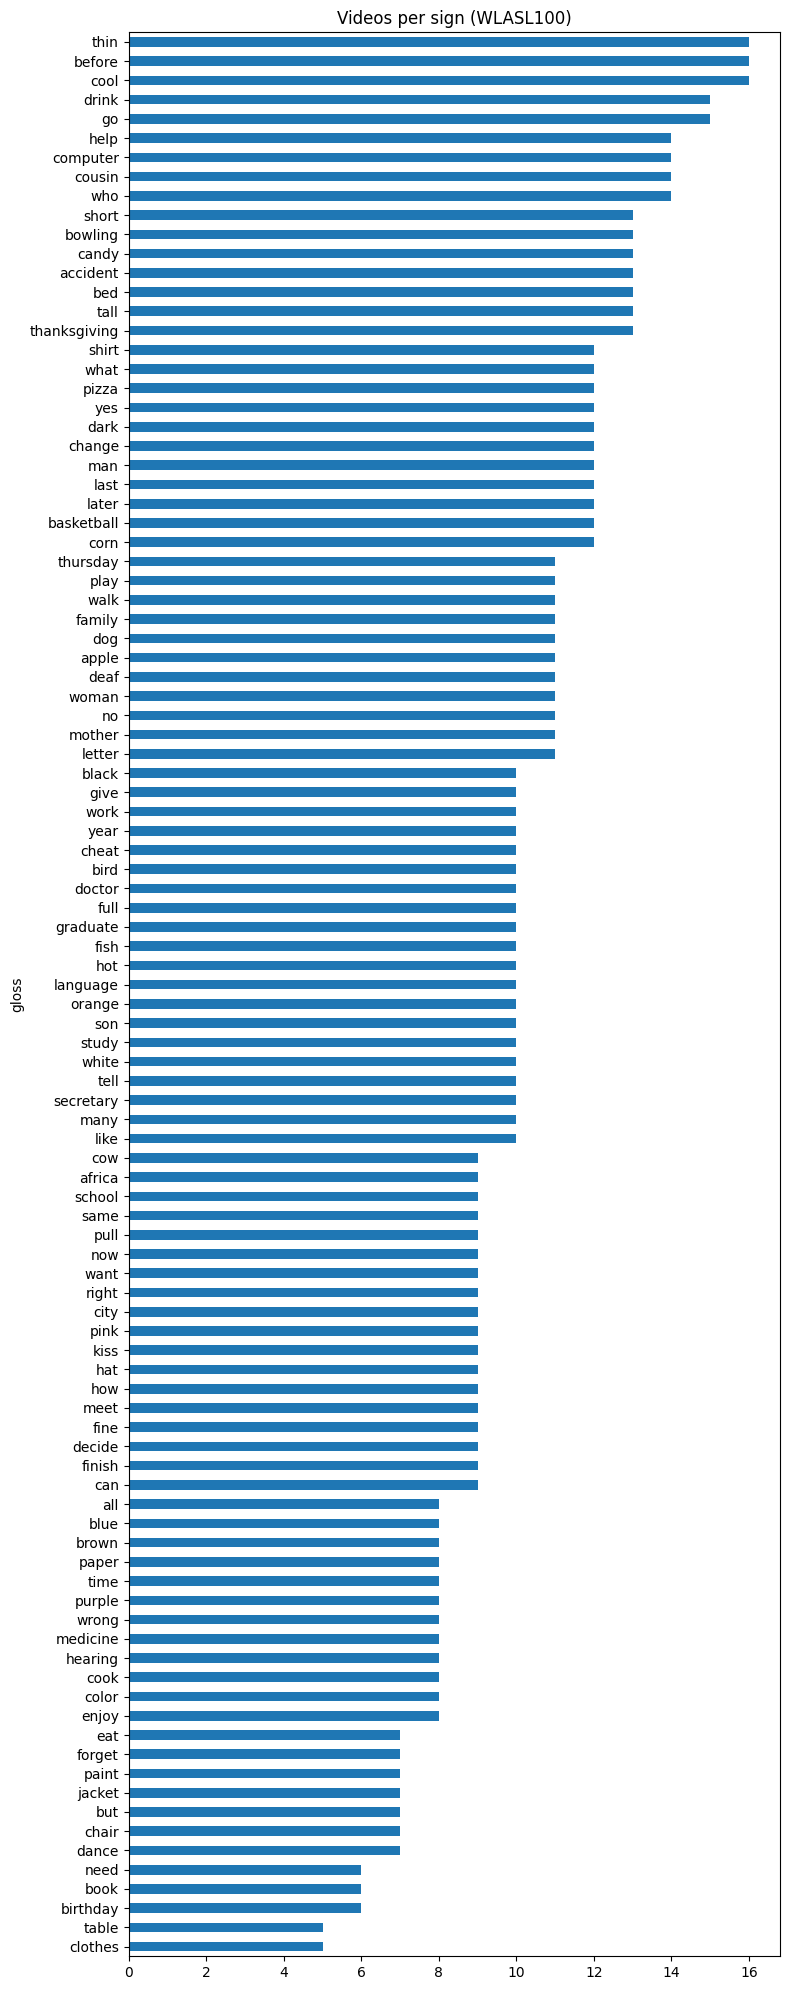

subset
train    748
val      165
test     100
Name: count, dtype: int64
subset    test  train  val
gloss                     
all          1      7    0
apple        0      8    3
bed          0     12    1
birthday     1      5    0
black        0      8    2
book         0      5    1
chair        0      5    2
clothes      1      4    0
cook         0      7    1
corn         2     10    0
dance        0      7    0
decide       0      7    2
eat          0      5    2
enjoy        0      7    1
family       0     10    1
forget       2      5    0
graduate     0      8    2
hat          0      8    1
hearing      1      7    0
hot          0      8    2
jacket       0      5    2
later        0      8    4
man          0     10    2
many         0      9    1
medicine     1      7    0
mother       0     10    1
need         0      5    1
orange       0      8    2
paint        0      5    2
paper        0      7    1
pink         0      8    1
school       0      7    2
son       

In [13]:
counts = ok.groupby('gloss').size().sort_values()
print(counts.describe())
print('largest/smallest class ratio:', counts.max() / counts.min())

fig, ax = plt.subplots(figsize=(8, 20))
counts.plot(kind='barh', ax=ax)
ax.set_title('Videos per sign (WLASL100)')
plt.tight_layout()
plt.savefig(f'{BASE}/videos_per_class.png', dpi=150)
plt.show()

print(ok['subset'].value_counts())
per_split = pd.crosstab(ok['gloss'], ok['subset'])
print(per_split[(per_split == 0).any(axis=1)])     # classes missing from some split

unique signers: 64
signer_id
11    164
12     83
4      67
10     61
13     58
36     54
38     45
59     33
31     31
41     31
Name: count, dtype: int64


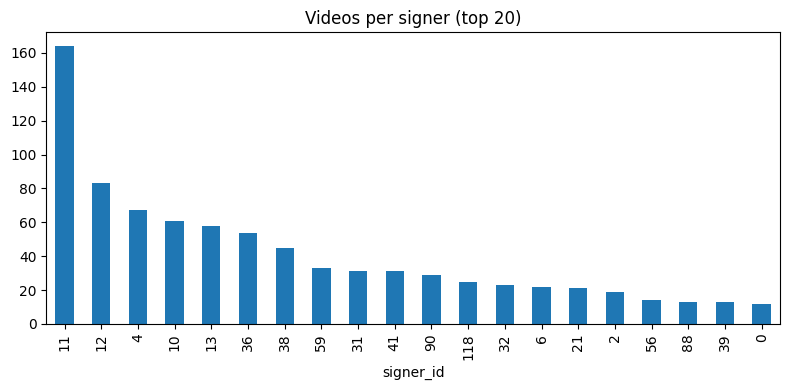

test signers also in train: 31 of 34
val signers also in train : 38 of 41


In [14]:
print('unique signers:', ok['signer_id'].nunique())
print(ok['signer_id'].value_counts().head(10))

fig, ax = plt.subplots(figsize=(8, 4))
ok['signer_id'].value_counts().head(20).plot(kind='bar', ax=ax)
ax.set_title('Videos per signer (top 20)')
plt.tight_layout()
plt.savefig(f'{BASE}/videos_per_signer.png', dpi=150)
plt.show()

tr = set(ok[ok.subset == 'train']['signer_id'])
va = set(ok[ok.subset == 'val']['signer_id'])
te = set(ok[ok.subset == 'test']['signer_id'])
print('test signers also in train:', len(te & tr), 'of', len(te))
print('val signers also in train :', len(va & tr), 'of', len(va))

In [15]:
print('duplicate video IDs:', ok['video_id'].duplicated().sum())          # should be 0

split_pct = (ok['subset'].value_counts(normalize=True) * 100).round(1)
print(split_pct)

# Does each video belong to exactly one split?
print(ok.groupby('video_id')['subset'].nunique().max())                   # should be 1

duplicate video IDs: 0
subset
train    73.8
val      16.3
test      9.9
Name: proportion, dtype: float64
1


In [16]:
from IPython.display import Video, display
import random

for _, r in ok.sample(3, random_state=1).iterrows():
    print(r['gloss'], '| signer', r['signer_id'], '| split', r['subset'])
    display(Video(f"{VIDEO_DIR}/{r['video_id']}.mp4", embed=True, width=320))

pink | signer 101 | split train


son | signer 38 | split train


cousin | signer 41 | split train
